# Step 4b-4 · All images at once: **VLM reads, pixels measure**, scored on every image

One run over every image that has ground truth:

| set | images | ground truth | how it is scored |
|---|---|---|---|
| `rebuilt` | the 12 plots rebuilt in `02_real_plots_multimodel` | exact (they were drawn from it) | as in `Auto_VLM_Digitization_3D` (rebuilt mode) |
| `gallery` | the synthetic gallery in `gallery/` (new chart types + 10 unsupported plots) | exact | as in `Auto_VLM_Digitization_3D` (gallery mode); unsupported plots only on *was it rejected* |
| `extended` | the original figures in `../data` and `../data/test_data` with hand-calibrated ground truth (`main_Hardcoded_ground_truth_generation`) | measured from pixels, checked by side-by-side | truth side with `chartbench.extended.score`, precision of every extracted item below |

The **extended** images go through `autodig.panels.process_figure`: the VLM first says whether the figure holds one plot, several panels or a plot with an inset; each plot is then read and digitized on its own (on a full-size masked copy, nothing cropped). Extracted panels are paired with the truth panels by frame overlap, series by name.

**Metrics** (a value is right when it is within 5 % of the axis span): hit rate = recall, accuracy = 100 − mean error, coverage = share of truth points with an extracted value, precision = share of extracted items that are right, F1.

**Saved** in `out_dir`: `<set>/<figure>/` (VLM answer, extracted CSV, recreated plot, points truth vs extracted), `side_by_side/<set>__<figure>.png` for manual checking (not shown under the cells), `status.csv`, `all_scores.csv`, `means.csv`, `metrics_*.png`.

VLM answers are cached: a second run costs nothing. Answers from earlier `Auto_VLM_Digitization_3D` runs (`outputs_qwen`) are reused.

In [1]:
# ============================ SETTINGS ============================
CONFIG = {
    "sets": ["rebuilt", "gallery", "extended"],     # which images to run (all three = every image with ground truth)
    "bench_dir": "../02_real_plots_multimodel",     # rebuilt plots, all ground truth, chartbench
    "data_dir": "../data",                          # originals of the extended set (data/ and data/test_data/)
    "gallery_dir": "gallery",                       # images/, truth/, specs/
    "out_dir": "outputs_all_qwen",                  # everything of this run goes here
    "reuse_answers_from": ["outputs_qwen"],         # earlier runs whose VLM answers are copied in (no second VLM call)

    "spec_source": "qwen",                          # "qwen": local Qwen3-VL (free) | "files": spec files, no VLM (dry run)
    "qwen_model": "Qwen/Qwen3-VL-4B-Instruct",
    "max_new_tokens": 1024,
    "upscale_below": 1000,                          # small images are enlarged for the VLM only
    "use_cache": True,                              # reuse saved VLM answers. False: ask again
    "pixel_check": True,                            # cross-check the VLM answer with the pixels, re-ask where they disagree
    "panel_sets": ["extended"],                     # sets whose figures may hold several plots (VLM layout question first)

    "hit_threshold": 5.0,                           # % of the axis span
    "show_worst": 0,                                # show the side-by-sides of the N worst plots under the cell (0 = none; all are saved)
}

In [2]:
import json, time, sys, shutil, warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)

sys.path.insert(0, ".")
import autodig
from autodig import QwenSpecReader, allsets as AS
from autodig.run import _jsonable
%matplotlib inline

OUT = Path(CONFIG["out_dir"]); OUT.mkdir(exist_ok=True)
SBS = OUT / "side_by_side"; SBS.mkdir(exist_ok=True)
items = AS.collect(CONFIG)
AS.seed_cache(items, OUT, CONFIG["reuse_answers_from"])
print(pd.Series([it["set"] for it in items]).value_counts().rename("images").to_string())
print("total:", len(items))

VLM answers reused from earlier runs: 0
extended    56
gallery     44
rebuilt     12
total: 112


## 0 · The VLM reader
Loaded lazily: if every answer is cached, the model is never loaded.

In [3]:
if CONFIG["spec_source"] == "qwen":
    reader = QwenSpecReader(CONFIG["qwen_model"], max_new_tokens=CONFIG["max_new_tokens"], upscale_below=CONFIG["upscale_below"])
else:   # dry run: spec files instead of a VLM (images without one fail and count as rejected)
    reader = AS.DrySpecReader(["manual_specs", Path(CONFIG["gallery_dir"]) / "specs"])
print("spec source:", type(reader).__name__, getattr(reader, "model_id", ""))
from autodig.panels import LAYOUT_PROMPT
print("\n--- layout question (extended set) ---\n" + LAYOUT_PROMPT)

spec source: QwenSpecReader Qwen/Qwen3-VL-4B-Instruct

--- layout question (extended set) ---
Look at the whole image. Does it contain ONE plot, or SEVERAL plots (panels side by side or
stacked, each with its own axes), or a main plot with a small INSET plot drawn inside it?
Return ONLY this JSON object:
{"layout": "single" or "panels" or "main+inset",
 "plots": [{"label": "<panel label as printed, e.g. (a), B, or empty>",
            "role": "main" or "panel" or "inset",
            "position": "<where: e.g. top-left, top-right, bottom, upper part, inside the main plot top-right>",
            "chart": "<what it is: line, scatter, bar, stacked bar, spectrum, ...>",
            "shares_axis_with": "<label of a plot whose printed x-axis (or y-axis) labels it uses, or empty>"}]}
Rules: an inset is a small plot with its own axes INSIDE another plot. A legend box or a printed table is not a plot.
Equations or fit-parameter tables printed inside a plot are not separate plots. List plots lef

## 1 · Read + digitize + recreate every image
One line per image. The side-by-sides are saved, not shown.

In [4]:
runs = {}
t0 = time.time()
for i, it in enumerate(items, 1):
    key = (it["set"], it["name"])
    r = AS.run_item(it, reader, OUT, CONFIG["use_cache"], CONFIG["pixel_check"], CONFIG["panel_sets"])
    runs[key] = r
    res = r["result"]
    n_pan = f"  panels: {len(r['panels'])}" if r.get("panels") else ""
    print(f"[{i:3d}/{len(items)}] {it['set']:8s} {it['name']:22s} {str(res.get('status')).upper():9s} "
          f"type: {res.get('chart_type')}{n_pan}  ({r['seconds']} s)" + (f"  ERROR {r['error'][:80]}" if r.get("error") else ""))
print(f"done in {(time.time() - t0) / 60:.1f} min")

[  1/112] rebuilt  ftir                   OK        type: line  (0.3 s)
[  2/112] rebuilt  pore                   OK        type: line  (0.3 s)
[  3/112] rebuilt  methane                OK        type: line  (0.4 s)
[  4/112] rebuilt  dosage                 OK        type: line  (0.6 s)
[  5/112] rebuilt  n2                     OK        type: scatter  (0.2 s)
[  6/112] rebuilt  kinetics               OK        type: line  (0.5 s)
[  7/112] rebuilt  ph                     OK        type: bar  (0.3 s)
[  8/112] rebuilt  concentration          OK        type: bar  (0.3 s)
[  9/112] rebuilt  concentration2         OK        type: bar  (0.4 s)
[ 10/112] rebuilt  climet                 OK        type: bar  (0.7 s)
[ 11/112] rebuilt  pie1                   OK        type: pie  (0.2 s)
[ 12/112] rebuilt  pie2                   OK        type: pie  (0.2 s)
[ 13/112] gallery  bar3d_1                OK        type: bar3d  (8.0 s)
[ 14/112] gallery  bar3d_2                OK        type: bar3d  (

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[ 98/112] extended scatter_4              OK        type: scatter  (26.7 s)
[ 99/112] extended scatter_5              REJECTED  type: scatter  (35.4 s)
[100/112] extended spectrum_1             OK        type: line  (32.2 s)
[101/112] extended spectrum_2             OK        type: line  (30.8 s)
[102/112] extended spectrum_3             REJECTED  type: line  (44.7 s)
[103/112] extended spectrum_4             OK        type: line  (32.4 s)
[104/112] extended spectrum_5             OK        type: line  (27.8 s)
[105/112] extended spectrum_6             OK        type: line  (28.3 s)
[106/112] extended bar_stacked_1          REJECTED  type: stacked_bar  (34.9 s)
[107/112] extended bar_stacked_2          REJECTED  type: stacked_bar  (33.3 s)
[108/112] extended bar_stacked_3          REJECTED  type: stacked_bar  (33.9 s)
[109/112] extended bar_stacked_4          REJECTED  type: stacked_bar  (39.1 s)
[110/112] extended bar_stacked_5          REJECTED  type: stacked_bar  (33.4 s)
[111/112] 

## 2 · Status of every image

In [5]:
status = pd.DataFrame([{"set": it["set"], "figure": it["name"], "status": runs[(it["set"], it["name"])]["result"].get("status"),
                        "chart type (VLM)": runs[(it["set"], it["name"])]["result"].get("chart_type"),
                        "layout": runs[(it["set"], it["name"])].get("layout", "single"),
                        "reason": "; ".join(runs[(it["set"], it["name"])]["result"].get("status_reasons", []))[:140]}
                       for it in items])
status.to_csv(OUT / "status.csv", index=False)
display(pd.crosstab(status["set"], status["status"], margins=True))
display(status[status["status"] != "ok"].set_index(["set", "figure"]))

status,flagged,ok,rejected,All
set,,,,
extended,2,35,19,56
gallery,3,31,10,44
rebuilt,0,12,0,12
All,5,78,29,112


status chart type (VLM)      layout                                                                           reason
set      figure                                                                                                                                    
gallery  scatter3d_2          flagged        scatter3d      single  depth not recoverable: no colour bar for z and no stems - x, y, z are guesse...
         scatter3d_3          flagged        scatter3d      single  depth from stem feet (experimental): a stem hidden behind another marker or ...
         surface3d_3          flagged        surface3d      single  depth not recoverable: no colour bar - the surface's z cannot be read from o...
         unknown_dendrogram  rejected            other      single                                                   unsupported chart type (other)
         unknown_micrograph  rejected            other      single                                                   unsupported chart type (other)
         unknown_multipanel  rejected             line      single  4 plot panels (axes frames) in one image - split the figure into single plot...
         unknown_network     rejected            other      single                                                   unsupported chart type (other)
         unknown_radar       rejected            polar      single  polar: angle calibration failed (6 angle labels found outside the circle, 0 ...
         unknown_schematic   rejected            other      single                                                   unsupported chart type (other)
         unknown_table       rejected            other      single                                                   unsupported chart type (other)
         unknown_ternary     rejected          scatter      single               self-check failed: x-axis has numeric tick labels = no (needs yes)
         unknown_venn        rejected            other      single                                                   unsupported chart type (other)
         unknown_violin      rejected            other      single                                                   unsupported chart type (other)
extended bar_1               rejected              bar      single                   self-check failed: bars found / expected = 3/9 (needs >= 50 %)
         bar_2               rejected              bar      single                   self-check failed: bars found / expected = 3/9 (needs >= 50 %)
         bar_3               rejected              bar      single                   self-check failed: bars found / expected = 3/9 (needs >= 50 %)
         feasibility         rejected      stacked_bar      single          self-check failed: bar segments found / expected = 7/18 (needs >= 75 %)
         nutrient_energy     rejected       main+inset  main+inset                                             panel_1: rejected; inset_2: rejected
         biosorption          flagged           panels      panels                                     a: ok; b: rejected; c: rejected; d: rejected
         sustainable          flagged           panels      panels  pH80MgPN111: rejected; pH95MgPN1412: rejected; pH95MgPN14115: rejected; pH95...
         line_1              rejected             line      single               self-check failed: x-axis has numeric tick labels = no (needs yes)
         line_11             rejected             line      single  self-check failed: x-axis has numeric tick labels = no (needs yes); self-che...
         line_12             rejected             line      single               self-check failed: x-axis has numeric tick labels = no (needs yes)
         line_13             rejected             line      single                    self-check failed: x axis label fit (px) = 6.8 (needs <= 3.0)
         scatter_1           rejected          scatter      single               self-check failed: x-axis has numeric tick labels = no (needs yes)
         scatter_3           reject

## 3 · Score every image against its ground truth
`<set>/<figure>/points_truth_vs_extracted.csv` holds every truth point with the extracted value; the side-by-side gets the scores in its caption.

In [6]:
rows = []
for it in items:
    r = runs[(it["set"], it["name"])]
    try:
        row, pts = AS.score_item(it, r, CONFIG["hit_threshold"])
    except Exception as e:
        row, pts = {"set": it["set"], "figure": it["name"], "status": r["result"].get("status"), "truth type": None,
                    "score error": f"{type(e).__name__}: {e}"}, None
    row["VLM s"] = AS.vlm_seconds(r)
    row["run s"] = r["seconds"]
    rows.append(row)
    if pts is not None and len(pts):
        pts.to_csv(Path(r["dir"]) / "points_truth_vs_extracted.csv", index=False)
    AS.titled_side_by_side(it, r, row, SBS / f"{it['set']}__{it['name']}.png")
scores = pd.DataFrame(rows)
first = ["set", "figure", "status", "truth type", "truth points", "hit rate %", "accuracy %", "coverage %",
         "precision %", "recall %", "F1 %", "extracted items"]
scores = scores[[c for c in first if c in scores] + [c for c in scores if c not in first]]
scores.to_csv(OUT / "all_scores.csv", index=False)
fails = scores[scores["score error"].notna()] if "score error" in scores else scores.iloc[:0]
if len(fails):
    print("could not score:"); display(fails[["set", "figure", "score error"]])
display(scores.set_index(["set", "figure"]).style.format(precision=1, na_rep="-")
        .apply(lambda r: ["background-color: #fde2e2" if r["status"] == "rejected" else
                          ("background-color: #fff3cd" if r["status"] == "flagged" else "") for _ in r], axis=1))
print("saved:", OUT / "all_scores.csv", "and", SBS)

saved: outputs_all_qwen/all_scores.csv and outputs_all_qwen/side_by_side


## 4 · Means per set and over all images
* **ok plots** — only plots the pipeline accepted (comparable with the per-set notebooks);
* **all supported plots** — end to end: a rejected or failed plot counts 0 for hit rate, recall and F1.

Unsupported gallery plots are not in the means; their score is whether they were rejected.

In [7]:
M = AS.means(scores)
M.to_csv(OUT / "means.csv")
display(M)
uns = scores[scores["truth type"] == "unsupported"]
if len(uns):
    print(f"unsupported gallery plots correctly rejected: {int(uns['rejected correctly'].sum())} / {len(uns)}")
gal = scores[(scores["set"] == "gallery") & (scores["truth type"] != "unsupported") & (scores["status"] == "ok")]
if len(gal):
    print("gallery, per chart type (ok plots):")
    display(gal.groupby("truth type")[["precision %", "recall %", "F1 %", "hit rate %", "accuracy %", "coverage %"]].mean().round(1))
ext = scores[scores["set"] == "extended"]
if len(ext) and "truth flagged in QA" in ext:
    q = ext[ext["truth flagged in QA"] == True]
    if len(q):
        print("extended figures whose ground truth itself was flagged in QA (check before trusting the score):", ", ".join(q["figure"]))

,scope,hit rate %,accuracy %,coverage %,precision %,recall %,F1 %,plots
extended,ok plots,57.4,69.5,75.7,55.4,57.4,53.5,35
gallery,ok plots,95.0,95.6,96.3,98.5,95.0,96.5,31
rebuilt,ok plots,99.4,99.7,100.0,98.1,96.6,97.3,12
ALL,ok plots,78.8,84.5,87.6,79.1,78.4,77.3,78
extended,all supported plots,45.3,56.7,62.6,43.7,45.3,42.3,56
gallery,all supported plots,90.1,93.1,94.5,94.3,90.1,91.8,34
rebuilt,all supported plots,99.4,99.7,100.0,98.1,96.6,97.3,12
ALL,all supported plots,66.6,73.9,77.6,67.0,66.3,65.3,102


unsupported gallery plots correctly rejected: 10 / 10
gallery, per chart type (ok plots):


,precision %,recall %,F1 %,hit rate %,accuracy %,coverage %
truth type,,,,,,
bar3d,100.0,85.0,91.8,85.0,84.5,85.0
box,100.0,98.0,99.0,98.0,97.8,98.0
field,99.4,97.1,98.2,97.1,97.8,98.2
heatmap,100.0,100.0,100.0,100.0,99.7,100.0
histogram,100.0,100.0,100.0,100.0,99.7,100.0
polar,100.0,100.0,100.0,100.0,99.3,100.0
scatter3d,100.0,73.3,84.6,73.3,90.3,100.0
stacked,100.0,99.0,99.5,99.0,98.5,99.0
surface3d,77.8,71.4,73.3,71.4,74.5,76.2


extended figures whose ground truth itself was flagged in QA (check before trusting the score): line_1, line_9, line_10, line_11, line_12


## 5 · Charts: accuracy, precision, recall, F1

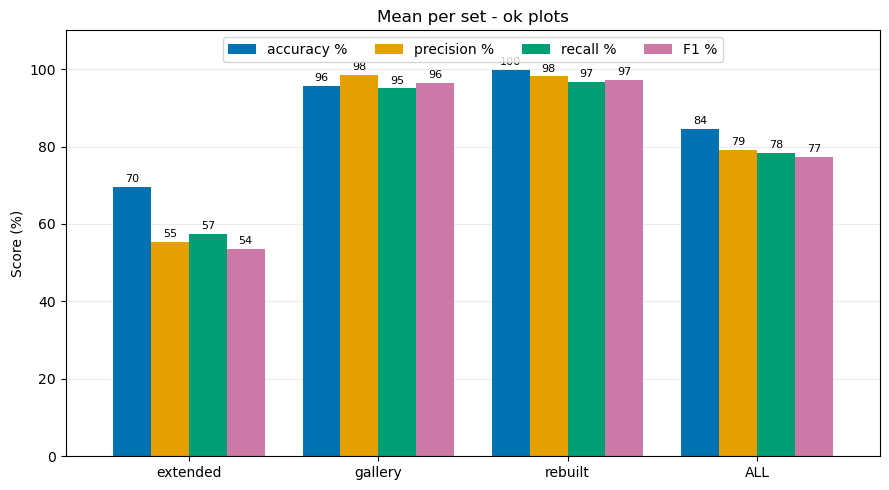

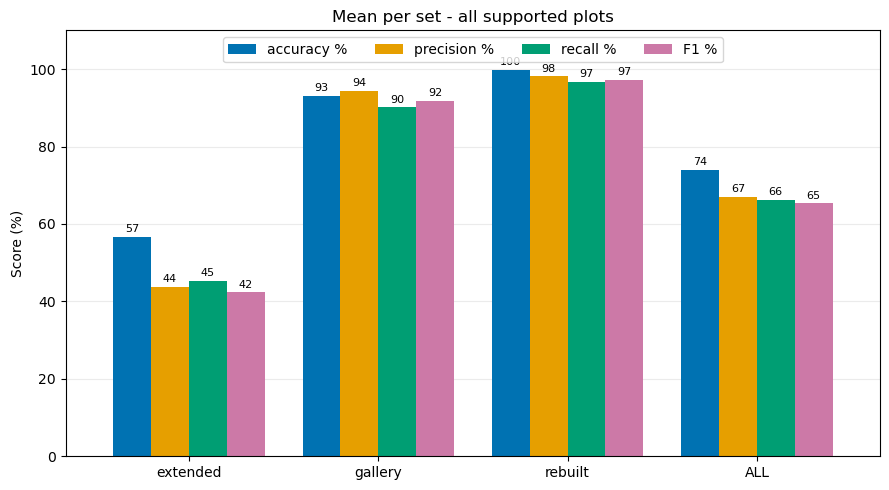

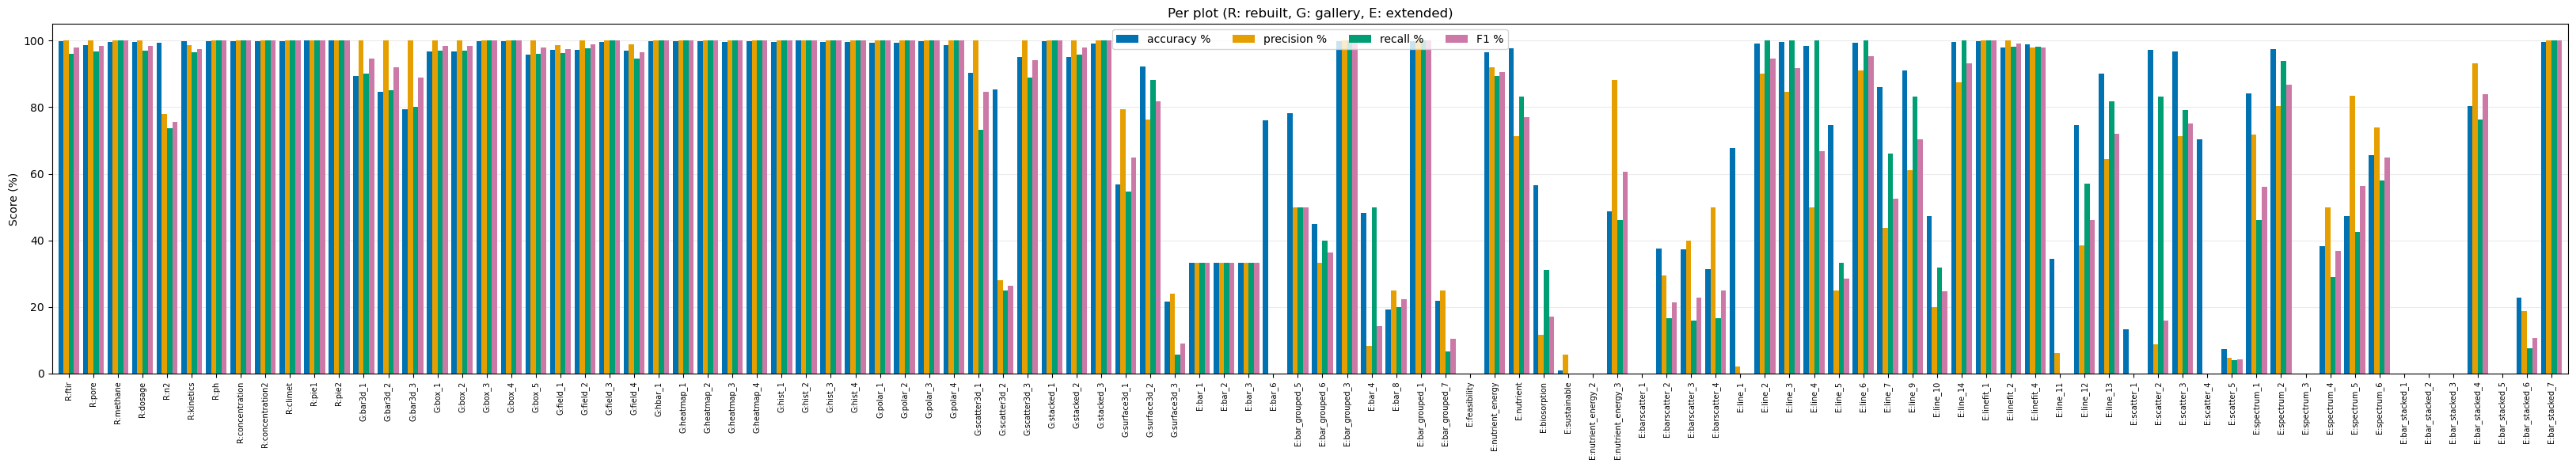

saved: metrics_mean_all_supported_plots.png, metrics_mean_ok_plots.png, metrics_per_plot.png


In [8]:
metric_columns = ["accuracy %", "precision %", "recall %", "F1 %"]
metric_colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
for scope in ("ok plots", "all supported plots"):
    m = M[M["scope"] == scope][metric_columns]
    if m.empty:
        continue
    fig, ax = plt.subplots(figsize=(9, 5))
    m.plot.bar(ax=ax, color=metric_colors, width=0.8)
    ax.set(title=f"Mean per set - {scope}", ylabel="Score (%)", ylim=(0, 110), xlabel="")
    ax.tick_params(axis="x", labelrotation=0); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(); fig.savefig(OUT / f"metrics_mean_{scope.replace(' ', '_')}.png", dpi=150); plt.show(); plt.close(fig)

per = scores[(scores["truth type"] != "unsupported") & (scores["truth points"].fillna(0) > 0)].copy()
per["label"] = per["set"].str[0].str.upper() + ":" + per["figure"]
per = per.set_index("label")[metric_columns].apply(pd.to_numeric, errors="coerce")
if len(per):
    fig, ax = plt.subplots(figsize=(max(14, 0.32 * len(per)), 6))
    per.plot.bar(ax=ax, color=metric_colors, width=0.85)
    ax.set(title="Per plot (R: rebuilt, G: gallery, E: extended)", ylabel="Score (%)", ylim=(0, 105), xlabel="")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7); ax.grid(axis="y", alpha=0.25); ax.set_axisbelow(True)
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(); fig.savefig(OUT / "metrics_per_plot.png", dpi=150); plt.show(); plt.close(fig)
print("saved:", ", ".join(p.name for p in OUT.glob("metrics_*.png")))

## 6 · Side-by-sides for manual checking
All are saved in `side_by_side/` (file name `<set>__<figure>.png`, scores in the caption). Below: the list sorted worst first; set `show_worst` > 0 to see those images here.

In [9]:
order = scores.assign(_f=pd.to_numeric(scores["F1 %"], errors="coerce").fillna(-1))
order = order[order["truth type"] != "unsupported"].sort_values(["_f", "hit rate %"])
worst = order[["set", "figure", "status", "F1 %", "hit rate %", "precision %"]].head(20)
display(worst.style.format(precision=1, na_rep="-").hide(axis="index").set_caption("20 lowest F1"))
for _, r in order.head(CONFIG["show_worst"]).iterrows():
    display(IPImage(filename=str(SBS / f"{r['set']}__{r['figure']}.png"), width=1400))

set,figure,status,F1 %,hit rate %,precision %
extended,bar_6,ok,0.0,0.0,0.0
extended,feasibility,rejected,0.0,0.0,0.0
extended,sustainable,flagged,0.0,0.0,5.6
extended,nutrient_energy_2,ok,0.0,0.0,0.0
extended,barscatter_1,ok,0.0,0.0,0.0
extended,line_1,rejected,0.0,0.0,2.2
extended,line_11,rejected,0.0,0.0,6.2
extended,scatter_1,rejected,0.0,0.0,0.0
extended,scatter_4,ok,0.0,0.0,0.0
extended,spectrum_3,rejected,0.0,0.0,0.0


In [10]:
# free the GPU / MPS memory
if hasattr(reader, "unload"):
    reader.unload()